# Why Britain voted Leave: data exploration (notebook 01)

**Project:** Why Britain voted Leave, and where the explanation breaks

**What the project asks:** in June 2016, 51.9% of UK voters chose to leave the European Union. But the vote was very different from place to place: 21% Leave in Lambeth, 76% in Boston. The project asks two things:

1. **What explains the Leave vote across areas?** Which kinds of places voted Leave, and which voted Remain?
2. **Where does that explanation break?** Which places don't fit the pattern, and why? Scotland is the main case.

**Where this notebook fits**

| Notebook | What it does |
|---|---|
| **01 Data exploration (this one)** | Looks at the data with charts and maps, to find the patterns |
| 02 Statistical tests | Tests whether the patterns are real and how big they are |
| 03 Scotland in depth | Compares Scotland's 2016 EU vote with its 2014 independence vote |
| 04 What-if scenario (optional) | Shows how a future independence vote could spread across councils, without predicting it |
| Tableau dashboards | Maps and charts to present the results (this notebook exports a file for them, in section 11) |
| Machine learning (later) | Predicts each area's Leave share and studies where the model fails |

**Goal of this notebook:** look at the cleaned data with charts **before** doing any formal statistics or machine learning. Exploring first is like reading a map before a journey: it shows us where to look. We want to find out:

1. How the Leave vote is spread across areas and regions.
2. Which area characteristics move with the Leave vote.
3. Where a simple explanation stops working, especially in Scotland and London.
4. How Remain 2016 compares with Yes 2014 in Scotland.
5. *(Optional)* How the Brexit debate on Twitter moved around the vote.

**Before running:** keep these files together in your `Data Project` folder. Its path is set in section 2.

- `gb_areas_clean.csv`: one row per voting area in Great Britain (380 rows)
- `scotland_2014_2016.csv`: one row per Scottish council (32 rows), with both referendums
- `tweets_daily_stance.csv`: one row per day of Brexit tweets (only needed for the optional section 10)
- `gb_areas_boundaries.geojson`: the outline of each area, for the maps

**Reminder:** every result describes **areas, not individual voters**. If an area with many graduates voted Remain, that doesn't tell us how each graduate in it voted.

## Key terms in simple words

| Term | Meaning |
|---|---|
| **Area** | One voting area, usually a local council. We have 380. |
| **Mean** | The average. |
| **Median** | The middle value when everything is sorted. Half the areas are below it and half above. |
| **Correlation (Pearson r)** | A number from -1 to +1 showing how closely two things move together in a straight line. |
| **p-value** | How easily a pattern could appear by chance alone. Below 0.05 usually means chance is an unlikely explanation. |
| **Trend line** | The straight line that best follows the dots on a chart. |
| **Residual (gap)** | The real result minus what the trend line expected. |
| **Outlier** | An area far from the pattern. |
| **Collinearity** | Two measures carry almost the same information, such as graduates and social grade AB. |
| **Social grade** | A rough class measure based on job type. AB is professional and managerial work, and DE is manual work, or people who aren't working. |
| **Claimant rate** | The share of working-age residents claiming unemployment-related benefits. |
| **Standard deviation** | How spread out the values are around the average. A small one means most areas are close to the average. |
| **Histogram** | A bar chart that counts how many areas fall into each band of values (for example, 50-55% Leave). |
| **Choropleth map** | A map where each area is coloured by a value, such as its Leave share. |
| **Weighted share** | A share calculated from total votes, so a big city counts more than a small district. An unweighted average counts every area once. |
| **UKIP 2014 share** | The share of votes won by UKIP, an anti-EU party, at the 2014 European election. It shows how Eurosceptic an area already was two years before the referendum. |

**How to read r**

- **r = +0.87:** when one goes up, the other usually goes up too.
- **r = -0.77:** when one goes up, the other usually goes down.
- **r close to 0:** there's no clear straight-line link.

Think of height and shoe size: taller people usually have bigger feet, so r is positive. **A correlation doesn't prove that one thing causes the other.**

## 1. Setup

We import the libraries and set one chart style, so every figure looks the same. We also fix one colour for each group, so Scotland and London are easy to follow from chart to chart.

**What this cell does**

- It imports the tools we need. Each library has one job: `pandas` for tables, `numpy` for maths, `matplotlib` and `seaborn` for charts, and `scipy` for statistical tests.
- It sets one chart style and fixes one colour for each group.

**Why it matters:** the rest of the notebook depends on this cell, so always run it first. Fixed colours help the reader, because Scotland is the same blue and London the same orange in every chart.

In [1]:
# pandas handles the tables, numpy the maths
import pandas as pd
import numpy as np

# matplotlib and seaborn draw the charts
import matplotlib.pyplot as plt
import seaborn as sns

# scipy gives us the p-value for a correlation
from scipy import stats

# Use the same clean style for every chart
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# One fixed colour per group, used in every chart
SCOTLAND = "#2a78d6"
LONDON = "#eb6834"
OTHER = "#b5b3ac"

## 2. Load the data

We tell Python which folder holds the files, load the three clean tables and print their size. We expect 380 areas, 32 Scottish councils and 45 days of tweets.

The tweets table is only used in the optional section 10. If you don't need it, the rest of the notebook still works.

**What this cell does**

- `DATA_DIR` stores the folder path once, so we don't repeat it for each file.
- `pd.read_csv()` turns each CSV file into a table, called a DataFrame.
- `.shape` shows the size of a table as (rows, columns).

**Why it matters:** checking the size straight away confirms we loaded the right files. We expect 380 areas, 32 Scottish councils and 45 days of tweets.

In [2]:
# Path handles folder locations safely, including spaces in folder names
from pathlib import Path

# The folder that holds the clean files
# Note: this path has a space after "IRONHACK DATA" and after "Data Project"
DATA_DIR = Path("../data")  # the data folder of this repository

# Load the three cleaned tables
areas = pd.read_csv(DATA_DIR / "gb_areas_clean.csv")
scotland = pd.read_csv(DATA_DIR / "scotland_2014_2016.csv")
tweets = pd.read_csv(DATA_DIR / "tweets_daily_stance.csv")

# Check each table has the expected number of rows
print("Areas:", areas.shape)
print("Scottish councils:", scotland.shape)
print("Tweet days:", tweets.shape)

Areas: (380, 26)
Scottish councils: (32, 17)
Tweet days: (45, 6)


**What this cell does:** `.head()` shows the first five rows of a few key columns, so we can see what one row looks like.

Each row in `areas` is one counting area, usually a local council. `leave_pct` is the share of valid votes for Leave, `turnout_pct` is the share of the electorate who voted, and `pct_degree` is the share of residents aged 16+ with a degree-level qualification.

In [3]:
# Look at the first rows and a few key columns
display(areas[["area", "region", "nation", "leave_pct", "turnout_pct", "pct_degree"]].head())

,area,region,nation,leave_pct,turnout_pct,pct_degree
0,Hartlepool,North East,England,69.5683,65.5862,17.5985
1,Middlesbrough,North East,England,65.4796,64.8892,18.5420
2,Redcar and Cleveland,North East,England,66.1881,70.2615,18.9288
3,Stockton-on-Tees,North East,England,61.7258,71.0035,22.8151
4,Darlington,North East,England,56.1832,71.0708,23.7169


## 3. Check the data before plotting

Charts can hide problems, so we check two things first:

- **Duplicates:** each area should appear once.
- **Missing values:** we need to know which columns have gaps.

`pct_nonuk_born` has no Scottish councils and `imd_score_england` covers England only. We keep these gaps instead of filling them, and we must not use these two columns in a Great Britain model.

**What this cell does**

- `.duplicated().sum()` counts repeated area codes. It should give 0.
- `.isna().sum()` counts the empty cells in each column. We then keep only the columns that have gaps.

**How to read the result:** `imd_score_england` is blank for 54 areas because it covers England only. `pct_nonuk_born` and its margin of error are blank for 40 areas, including all of Scotland. Isles of Scilly has no pay or child poverty value.

In [4]:
# Each area code should appear only once
print("Duplicate area codes:", areas["code"].duplicated().sum())

# Count the missing values and keep only columns that have some
missing = areas.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

Duplicate area codes: 0
imd_score_england     54
nonuk_ci_thousands    40
pct_nonuk_born        40
median_weekly_pay      1
child_poverty_pct      1
dtype: int64


**What this cell does:** `.describe()` summarises one column in a few numbers: the count, mean, standard deviation, minimum, maximum and quartiles. The 25%, 50% and 75% rows are the values below which that share of areas falls. The 50% row is the median.

In [5]:
# Summary statistics for the Leave share
display(areas["leave_pct"].describe().round(1).to_frame())

,leave_pct
count,380.0
mean,53.1
std,10.4
min,21.4
25%,47.2
50%,54.3
75%,60.4
max,75.6


**What we see:** the median area had 54.3% Leave, and the areas run from 21.4% in Lambeth to 75.6% in Boston.

**Why is the national result (51.9%) lower than the median area (54.3%)?** Here each area counts once, whatever its size. Remain was strong in many large urban areas (London boroughs, big cities), which hold many voters. Counting votes, those big Remain areas pull the national result down. Counting areas, they are just a few rows among 380.

## 4. How was the Leave vote spread across areas?

A histogram shows how many areas fall into each band of Leave share. The dashed line marks 50%, the point where an area voted Leave.

Each area counts once here, whatever its size. So this chart shows the map of areas, not the national result.

**What this cell does**

- `areas["leave_pct"] > 50` marks each area True or False, and `.sum()` counts the True values.
- `ax.hist()` sorts the areas into bands 5 points wide and draws one bar per band.
- `ax.axvline(50)` draws the dashed line at 50%.

**How to read this chart:** each bar shows how many areas fall in a band of Leave share. Tall bars mean many areas had a result in that range. Bars to the right of the dashed line are areas that voted Leave.

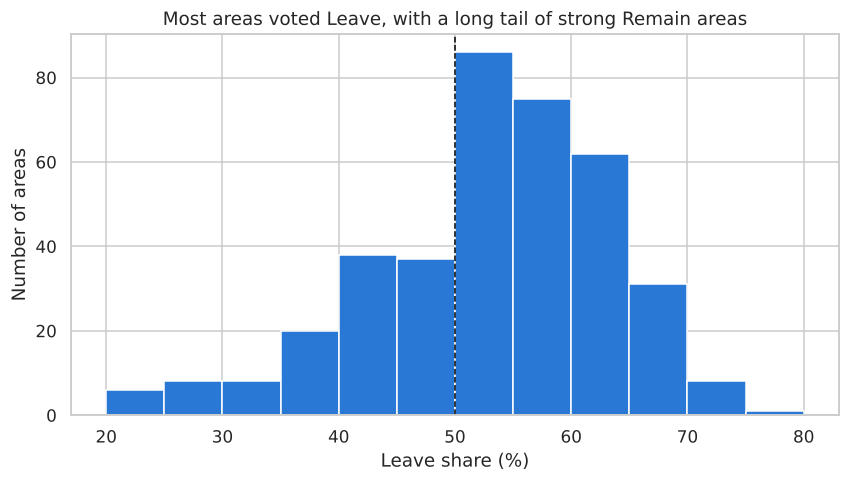

263 of 380 areas voted Leave


In [6]:
# Count how many areas passed 50% Leave
n_leave = (areas["leave_pct"] > 50).sum()
print(f"{n_leave} of {len(areas)} areas voted Leave")

# Draw the histogram with bins 5 points wide
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(areas["leave_pct"], bins=np.arange(20, 85, 5), color=SCOTLAND, edgecolor="white")

# Mark the 50% line
ax.axvline(50, color="black", linestyle="--", linewidth=1)

# Add a title and axis labels
ax.set_title("Most areas voted Leave, with a long tail of strong Remain areas")
ax.set_xlabel("Leave share (%)")
ax.set_ylabel("Number of areas")
plt.show()

**What we see**

- 263 of the 380 areas voted Leave, about 7 in 10.
- The tallest bar is just past the line: 86 areas had between 50% and 55% Leave.
- The bars fall away slowly on the Remain side. This is the long left tail, where a smaller group of areas voted strongly Remain. It also pulls the mean (53.1%) below the median (54.3%).

**Why it matters:** many areas were close to 50%, so a small change there could flip an area's result without changing much in the data. That's why we'll model the Leave share itself, not just Leave or Remain.

## 5. How does the vote differ by region?

We plot every area as a dot, grouped by region and sorted by median Leave share. This shows more than an average, because we can see how spread out each region is.

**What this cell does**

- It works out each region's median and sorts the regions by it.
- `sns.stripplot()` draws one dot per area, with a little random spread so dots don't sit on top of each other.
- The black marks show each region's median.

**How to read this chart:** each row is a region and each dot is one area in it. Dots further right mean a higher Leave share. A tight group means the areas voted alike, and a wide spread means they differed. The up-and-down spread within a row has no meaning.

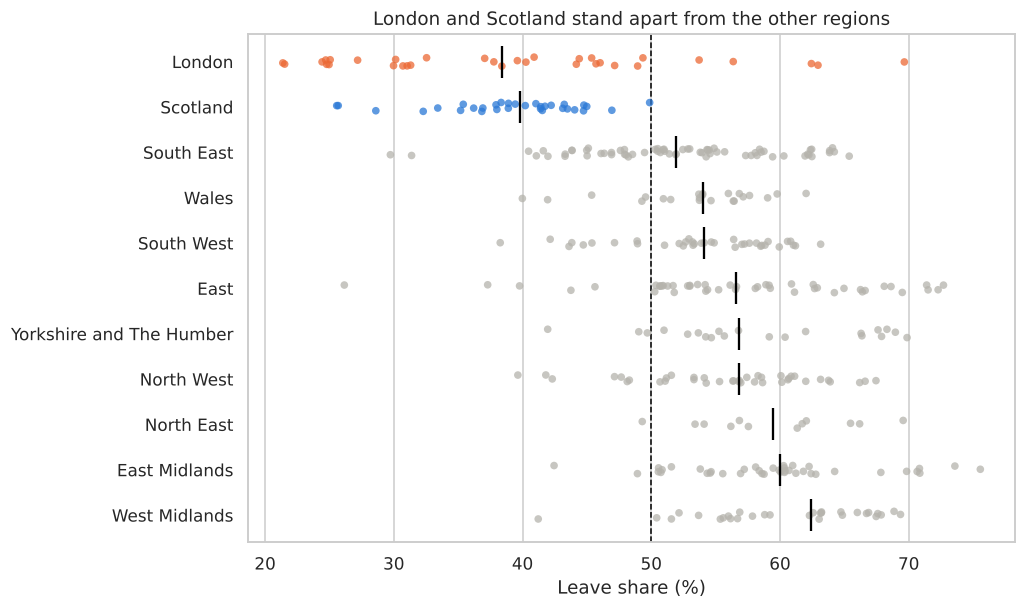

In [7]:
# Sort regions from lowest to highest median Leave share
order = areas.groupby("region")["leave_pct"].median().sort_values().index

# Give Scotland and London their own colours
palette = {region: OTHER for region in order}
palette["Scotland"] = SCOTLAND
palette["London"] = LONDON

# Draw one dot per area
fig, ax = plt.subplots(figsize=(9, 6))
sns.stripplot(data=areas, x="leave_pct", y="region", hue="region", order=order,
              palette=palette, size=5, alpha=0.75, legend=False, ax=ax)

# Add a black mark at each region's median
medians = areas.groupby("region")["leave_pct"].median().reindex(order)
ax.scatter(medians.values, range(len(medians)), marker="|", s=450, color="black", zorder=3)

# Mark the 50% line and label the chart
ax.axvline(50, color="black", linestyle="--", linewidth=1)
ax.set_title("London and Scotland stand apart from the other regions")
ax.set_xlabel("Leave share (%)")
ax.set_ylabel("")
plt.show()

**What we see**

- London (38.4%) and Scotland (39.8%) have the lowest medians, and the West Midlands has the highest (62.4%).
- No Scottish council reached 50%. The closest was Moray at 49.9%.
- London has the widest spread, 48.3 points, from Lambeth (21.4%) to Havering (69.7%).
- The East also varies widely, from Cambridge at 26.2% to Thurrock at 72.3%.

**Why it matters:** a region's average can hide very different areas. "London voted Remain" is true overall, but several outer boroughs voted Leave.

**What this cell does:** `.groupby("region")` splits the areas by region, and `.agg()` works out the lowest value, median, highest value and number of areas for each one. This gives the exact numbers behind the chart above.

In [8]:
# Compare each region's median and range in a table
region_table = areas.groupby("region")["leave_pct"].agg(["min", "median", "max", "count"])
display(region_table.sort_values("median").round(1))

,min,median,max,count
region,,,,
London,21.4,38.4,69.7,33
Scotland,25.6,39.8,49.9,32
South East,29.7,51.9,65.4,67
Wales,40.0,54.0,62.0,22
South West,38.3,54.1,63.2,37
East,26.2,56.5,72.7,47
Yorkshire and The Humber,42.0,56.8,69.9,21
North West,39.6,56.8,67.5,39
North East,49.3,59.4,69.6,12


## 6. Where were the votes? Maps of areas and regions

A map shows patterns that charts can hide, such as Remain clusters around cities.

The CSV files contain no shapes, so we load `gb_areas_boundaries.geojson`, which holds the outline of each area. Each outline has the same area code as our table, so we can colour it with that area's vote.

Keep that file in the same folder as the CSV files.

The colours run from blue (Remain) to orange (Leave), with the palest colour at 50%. Large rural areas fill much of the map but hold fewer voters, so a map shows geography, not the size of the vote.

**What this cell does, step by step**

1. It loads the outlines of all 380 areas from the boundary file.
2. It works out each region's Leave share from its total votes. A simple average would give tiny areas the same weight as large cities.
3. It creates the colour scale, with blue for Remain, pale at 50% and orange for Leave.
4. It lists every outline with its area code. An area can have several shapes, such as islands.
5. `draw_map()` colours each shape using its area code. We make this a function because we use it for three maps.
6. It adds the region labels and one colour key for both maps.

**How to read these maps:** the colour shows the vote, and the shape shows the place. Stronger blue means a stronger Remain vote, stronger orange means a stronger Leave vote, and pale areas were close to 50%. On the left, each area has its own colour. On the right, all areas in a region share one colour.

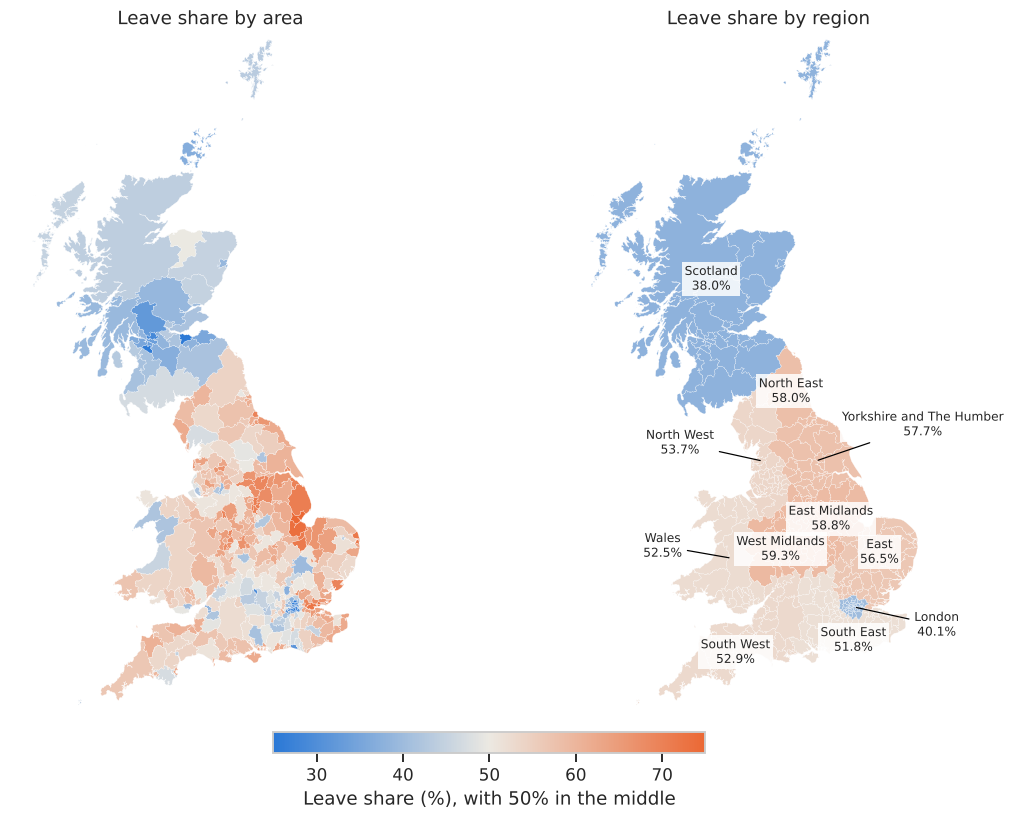

Outlines loaded: 380 areas


In [9]:
# json reads the boundary file
import json

# These matplotlib tools draw shapes and colour them by value
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Load the outlines file from the same folder as the CSV files
with open(DATA_DIR / "gb_areas_boundaries.geojson") as file:
    boundaries = json.load(file)
print("Outlines loaded:", len(boundaries["features"]), "areas")

# Regional Leave share: add up the votes first, so large areas count for more
region_votes = areas.groupby("region")[["leave_votes", "valid_votes"]].sum()
region_leave = 100 * region_votes["leave_votes"] / region_votes["valid_votes"]

# Look up each area's own share and its region's share by area code
leave_by_area = areas.set_index("code")["leave_pct"]
leave_by_region = areas.set_index("code")["region"].map(region_leave)

# Blue for Remain, pale at 50%, orange for Leave
vote_colours = LinearSegmentedColormap.from_list("vote", [SCOTLAND, "#ece9e2", LONDON])
vote_scale = TwoSlopeNorm(vmin=25, vcenter=50, vmax=75)

# Turn the file into a list of outlines, with the area code for each one
shapes = []
shape_codes = []
for feature in boundaries["features"]:
    for polygon in feature["geometry"]["coordinates"]:
        # The first ring is the outer edge. Later rings would be holes
        shapes.append(polygon[0])
        shape_codes.append(feature["properties"]["code"])

def draw_map(ax, values, title):
    """Draw every outline, coloured by the value for its area code."""
    colours = [values[code] for code in shape_codes]
    layer = PolyCollection(shapes, array=colours, cmap=vote_colours, norm=vote_scale, edgecolors="white", linewidths=0.15)
    ax.add_collection(layer)
    ax.set_xlim(-8.3, 3.2)
    ax.set_ylim(49.8, 60.95)

    # One degree of longitude is shorter than one of latitude here, so we correct the shape
    ax.set_aspect(1.75)
    ax.set_axis_off()
    ax.set_title(title)
    return layer

# Two maps side by side
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 8.5))
layer = draw_map(left, leave_by_area, "Leave share by area")
draw_map(right, leave_by_region, "Leave share by region")

# Label positions, as (longitude, latitude), chosen by hand so labels don't overlap
inside_labels = {
    "Scotland": (-4.2, 56.9), "North East": (-1.9, 55.05), "East Midlands": (-0.75, 52.95),
    "West Midlands": (-2.2, 52.45), "East": (0.65, 52.4), "South East": (-0.1, 50.95), "South West": (-3.5, 50.75),
}

# These labels sit at sea, each with a line to its region: (label position, region position)
sea_labels = {
    "North West": ((-5.1, 54.2), (-2.7, 53.9)),
    "Yorkshire and The Humber": ((1.9, 54.5), (-1.2, 53.9)),
    "Wales": ((-5.6, 52.5), (-3.6, 52.3)),
    "London": ((2.3, 51.2), (-0.1, 51.5)),
}

# Write each region's name and share on the map
label_box = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
for region, position in inside_labels.items():
    right.text(*position, f"{region}\n{region_leave[region]:.1f}%", ha="center", va="center", fontsize=8, bbox=label_box)
for region, (position, target) in sea_labels.items():
    right.annotate(f"{region}\n{region_leave[region]:.1f}%", xy=target, xytext=position, ha="center", va="center", fontsize=8,
                   bbox=label_box, arrowprops=dict(arrowstyle="-", color="black", linewidth=0.8))

# One shared colour key for both maps
fig.colorbar(layer, ax=[left, right], orientation="horizontal", fraction=0.03, pad=0.03, label="Leave share (%), with 50% in the middle")
plt.show()

**What this cell does**

- It keeps only London's 33 areas, the 32 boroughs and the City of London, and ranks them by Leave share. The neighbouring counties are left out so the map is easier to read.
- It draws the boroughs with the same colours as the national map.
- It writes each borough's rank number on the map, using its largest shape to place the number.
- It adds a ranked bar chart, so we can match each number to a name and an exact value.

**How to read this chart:** find a number on the map, then look up that number in the list on the right. Number 1 had the lowest Leave share and number 33 the highest. Blue boroughs voted Remain and orange boroughs voted Leave. The dashed line in the list marks 50%. The white strip through the middle of the map is the River Thames.


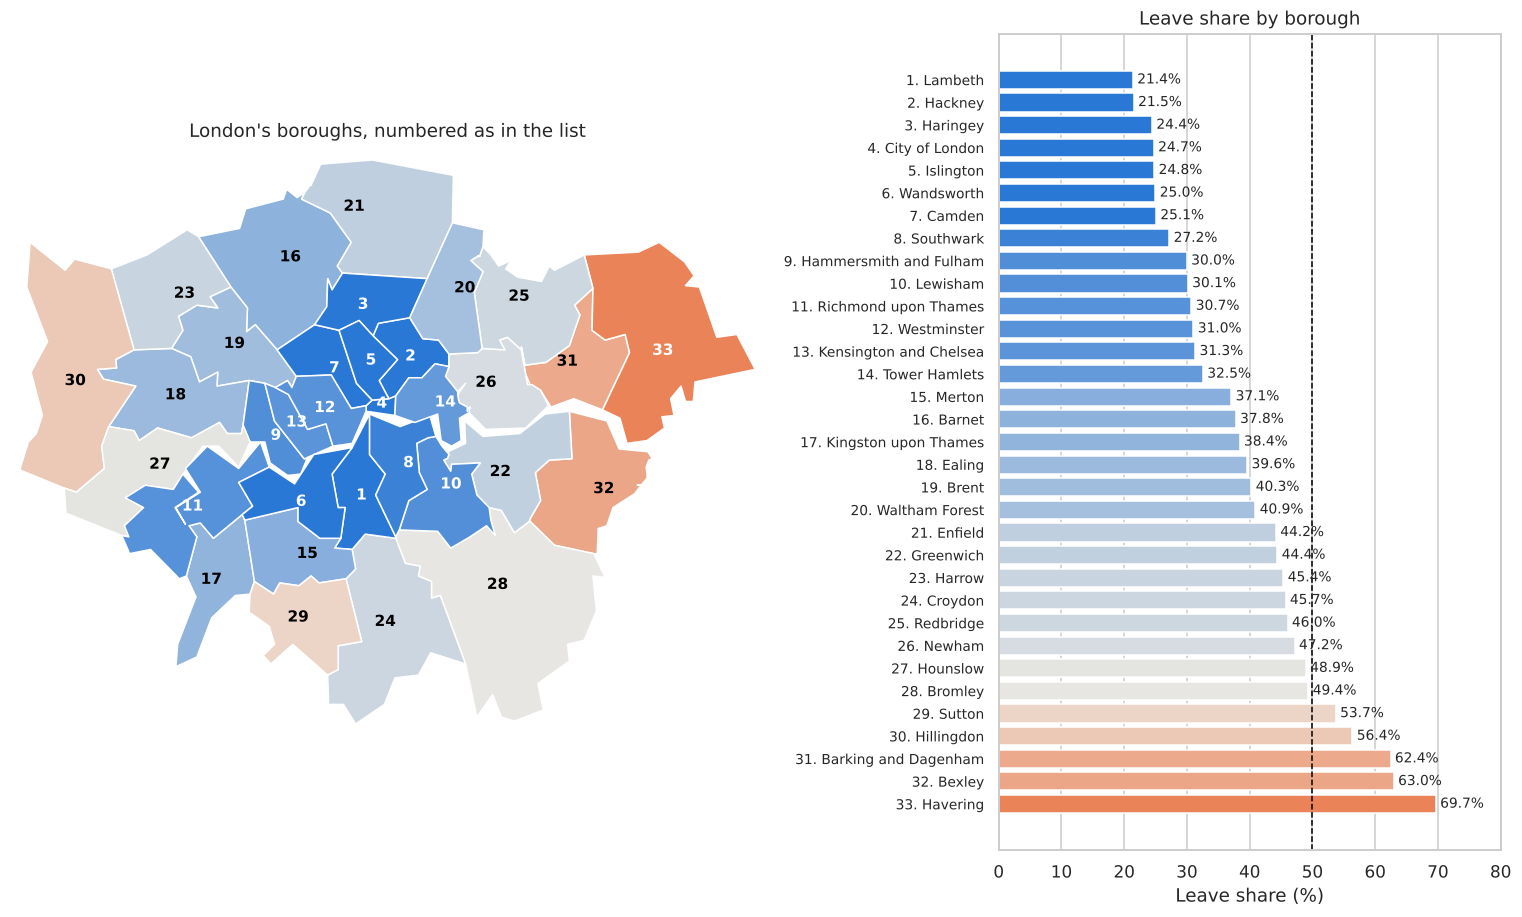

5 of 33 boroughs voted Leave


In [10]:
# Keep only London's boroughs and rank them from lowest to highest Leave share
london = areas[areas["region"] == "London"].sort_values("leave_pct").reset_index(drop=True)
london["rank"] = london.index + 1

# Collect the outlines of the London boroughs only
london_shapes = []
london_codes = []
for code, shape in zip(shape_codes, shapes):
    if code in set(london["code"]):
        london_shapes.append(shape)
        london_codes.append(code)

# Find each borough's largest shape, so its number sits in the right place
largest = {}
for code, shape in zip(london_codes, london_shapes):
    if code not in largest or len(shape) > len(largest[code]):
        largest[code] = shape

# Map on the left and ranked bars on the right
fig, (map_ax, bar_ax) = plt.subplots(1, 2, figsize=(14, 8.5), gridspec_kw={"width_ratios": [1.5, 1]})

# Draw the boroughs with the same colours as the national map
colours = [leave_by_area[code] for code in london_codes]
map_ax.add_collection(PolyCollection(london_shapes, array=colours, cmap=vote_colours, norm=vote_scale,
                                     edgecolors="white", linewidths=1))

# Fit the map to London and correct its shape
map_points = np.vstack(london_shapes)
map_ax.set_xlim(map_points[:, 0].min() - 0.01, map_points[:, 0].max() + 0.01)
map_ax.set_ylim(map_points[:, 1].min() - 0.01, map_points[:, 1].max() + 0.01)
map_ax.set_aspect(1.6)
map_ax.set_axis_off()
map_ax.set_title("London's boroughs, numbered as in the list")

# Write each borough's number on the map, in white on the darkest colours
for _, borough in london.iterrows():
    x, y = np.array(largest[borough["code"]]).mean(axis=0)
    text_colour = "white" if borough["leave_pct"] < 33 or borough["leave_pct"] > 67 else "black"
    map_ax.text(x, y, str(borough["rank"]), ha="center", va="center", fontsize=10, fontweight="bold", color=text_colour)

# One bar per borough, with the lowest Leave share at the top
bar_ax.barh(london["rank"], london["leave_pct"], color=vote_colours(vote_scale(london["leave_pct"])))
bar_ax.set_yticks(london["rank"])
bar_ax.set_yticklabels([f'{row["rank"]}. {row["area"]}' for _, row in london.iterrows()], fontsize=9)
bar_ax.invert_yaxis()

# Mark 50% and write each value beside its bar
bar_ax.axvline(50, color="black", linestyle="--", linewidth=1)
for _, borough in london.iterrows():
    bar_ax.text(borough["leave_pct"] + 0.7, borough["rank"], f'{borough["leave_pct"]:.1f}%', va="center", fontsize=9)

bar_ax.set_xlim(0, 80)
bar_ax.set_xlabel("Leave share (%)")
bar_ax.set_title("Leave share by borough")
bar_ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# How many boroughs voted Leave?
print((london["leave_pct"] > 50).sum(), "of", len(london), "boroughs voted Leave")

**What we see**

- **Scotland** is blue across the country, including its rural areas. So Remain there isn't only an urban pattern.
- **Remain cities** stand out in England and Wales: Cambridge (26.2% Leave), Oxford (29.7%), Bristol (38.3%), Manchester (39.6%) and Liverpool (41.8%).
- **Eastern England** has the strongest Leave areas, such as Boston (75.6%).
- **London** splits between inner and outer boroughs. Lambeth and Hackney are close to 21% Leave, while Havering in the far east is at 69.7%. Only 5 of the 33 London areas voted Leave: Sutton, Hillingdon, Barking and Dagenham, Bexley and Havering.

**Be careful:** large rural areas fill much of the map but hold fewer voters. A map shows where votes were, not how many there were.

Boundaries contain Ordnance Survey data © Crown copyright and database right 2014, and ONS data © Crown copyright 2014, via [UK-GeoJSON by Martin Chorley](https://github.com/martinjc/UK-GeoJSON) (CC BY 4.0). They are simplified for mapping, so don't use them to measure areas.

### Interactive map

This map runs inside the notebook. You can change what it shows without changing any code.

**What this cell does**

1. It imports Plotly, a library for interactive charts. If Plotly is missing, the cell prints how to install it, and the rest of the notebook still runs.
2. `views` lists the measures the map can show, with the colours and scale for each one.
3. `go.Choropleth` draws the map and colours each outline by its area code.
4. `updatemenus` adds the two dropdowns. **Map view** swaps the values shown, and **Zoom to** moves the map.

**How to use it**

- Choose a measure from **Map view** and a place from **Zoom to**.
- Hover over an area to see its name, region and value.
- Scroll to zoom, drag to move, and double-click to reset the map.

**How to read it:** in vote views, blue means Remain or below the trend, orange means Leave or above the trend, and the palest colour is the midpoint. In the other views, darker purple means a higher value. Grey areas have no data.

The map needs an internet connection the first time it draws. It may also appear only after you run the cell, because Plotly maps aren't always saved in the notebook.

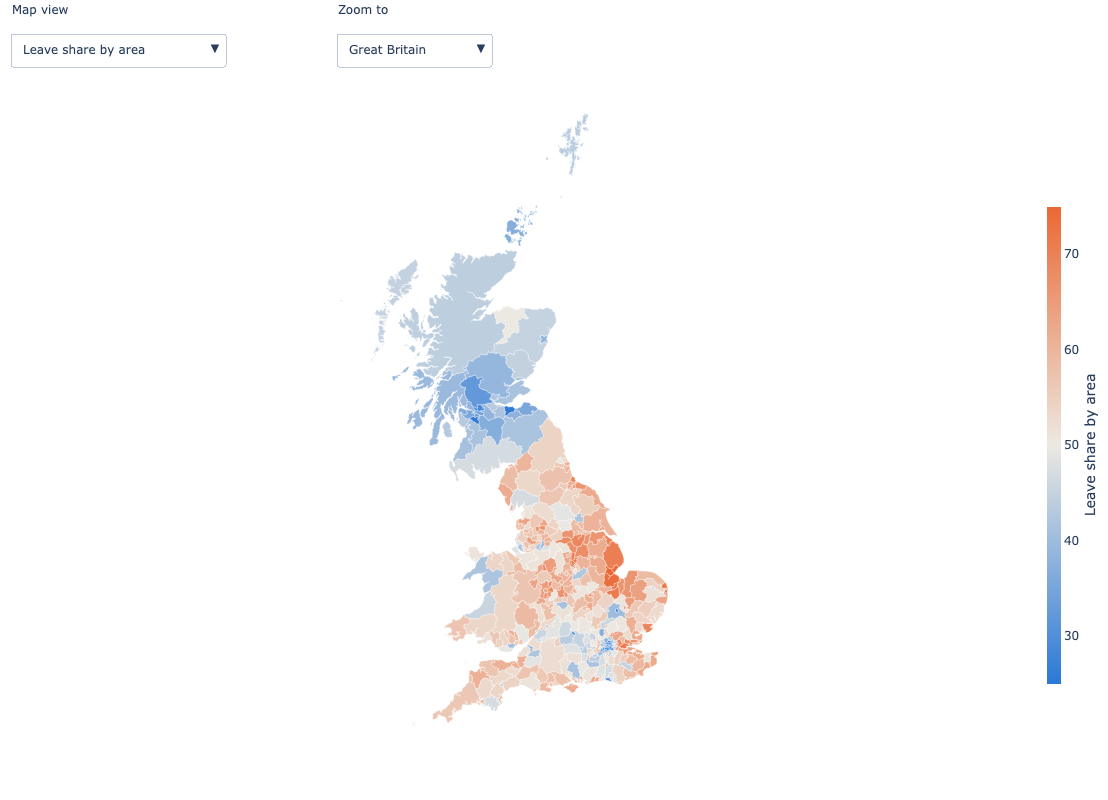

In [11]:
# Plotly draws interactive charts inside the notebook
try:
    import plotly.graph_objects as go
except ImportError:
    go = None
    print("Plotly is missing. Run this in a new cell, then restart the kernel: %pip install plotly")

# This table holds everything the map can show
map_data = areas.copy()
map_data["region_leave_pct"] = map_data["region"].map(region_leave)

# The graduate trend, fitted outside Scotland and London
rest_of_gb = map_data[(map_data["nation"] != "Scotland") & (map_data["region"] != "London")]
trend_slope, trend_intercept = np.polyfit(rest_of_gb["pct_degree"], rest_of_gb["leave_pct"], deg=1)
map_data["trend_gap"] = map_data["leave_pct"] - (trend_intercept + trend_slope * map_data["pct_degree"])

# The Yes vote exists for Scottish councils only
map_data["yes_2014_pct"] = map_data["code"].map(scotland.set_index("code")["yes_pct"])

# Colour scales: blue to orange around a midpoint, or pale to dark purple
VOTE_SCALE = [[0, SCOTLAND], [0.5, "#ece9e2"], [1, LONDON]]
PURPLE_SCALE = [[0, "#e6e4f3"], [1, "#4a3f9f"]]

# Each view: menu name, column, colours, lowest value, highest value and unit
views = [
    ("Leave share by area", "leave_pct", VOTE_SCALE, 25, 75, "%"),
    ("Leave share by region", "region_leave_pct", VOTE_SCALE, 25, 75, "%"),
    ("Gap from the graduate trend", "trend_gap", VOTE_SCALE, -25, 25, " pts"),
    ("Yes vote 2014 (Scotland)", "yes_2014_pct", VOTE_SCALE, 30, 70, "%"),
    ("Graduates", "pct_degree", PURPLE_SCALE, 10, 60, "%"),
    ("UKIP 2014 share", "ukip_2014_pct", PURPLE_SCALE, 5, 50, "%"),
    ("Referendum turnout", "turnout_pct", PURPLE_SCALE, 55, 85, "%"),
    ("Claimant rate", "claimant_rate", PURPLE_SCALE, 0, 5, "%"),
]

def view_settings(name, column, colours, low, high, unit):
    """Collect the values and colour settings for one view."""
    values = map_data[column].round(1)

    # Hover text for each area. Blank values show as "No data"
    labels = [f"{area}<br>{region}<br>{name}: {'No data' if pd.isna(value) else str(value) + unit}"
              for area, region, value in zip(map_data["area"], map_data["region"], values)]

    # Plotly needs None, not NaN, for blank values
    z = [None if pd.isna(value) else value for value in values]
    return {"z": [z], "text": [labels], "colorscale": [colours], "zmin": low, "zmax": high, "colorbar.title.text": name}

# Places for the zoom menu: centre of the map and how far to zoom in
places = [
    ("Great Britain", 55.3, -3.3, 16),
    ("England and Wales", 52.7, -1.8, 21),
    ("Scotland", 57.6, -4.5, 26),
    ("Wales", 52.35, -3.7, 52),
    ("London", 51.49, -0.11, 500),
]

if go is not None:
    # Start with the first view
    first = view_settings(*views[0])

    # Draw the map once. The menus only change its settings
    fig = go.Figure(data=[dict(
        type="choropleth",
        geojson=boundaries,
        featureidkey="properties.code",
        locations=list(map_data["code"]),
        z=first["z"][0],
        text=first["text"][0],
        hovertemplate="%{text}<extra></extra>",
        colorscale=first["colorscale"][0],
        zmin=first["zmin"],
        zmax=first["zmax"],
        colorbar=dict(title=dict(text=views[0][0], side="right"), thickness=14, len=0.7),
        marker=dict(line=dict(color="white", width=0.3)),
    )])

    # One menu entry for each view
    view_menu = [dict(label=view[0], method="restyle", args=[view_settings(*view)]) for view in views]

    # One menu entry for each place
    place_menu = [dict(label=name, method="relayout",
                       args=[{"geo.center.lat": lat, "geo.center.lon": lon, "geo.projection.scale": scale}])
                  for name, lat, lon, scale in places]

    # Set the map's starting position, and place the two menus at the top
    fig.update_layout(
        height=800,
        margin=dict(l=0, r=0, t=90, b=0),
        geo=dict(
            visible=False,
            projection=dict(type="mercator", scale=places[0][3]),
            center=dict(lat=places[0][1], lon=places[0][2]),
        ),
        updatemenus=[
            dict(buttons=view_menu, direction="down", x=0.01, xanchor="left", y=1.08, yanchor="top"),
            dict(buttons=place_menu, direction="down", x=0.33, xanchor="left", y=1.08, yanchor="top"),
        ],
        annotations=[
            dict(text="Map view", x=0.01, xref="paper", xanchor="left", y=1.1, yref="paper", yanchor="bottom", showarrow=False),
            dict(text="Zoom to", x=0.33, xref="paper", xanchor="left", y=1.1, yref="paper", yanchor="bottom", showarrow=False),
        ],
    )
    fig.show()

## 7. Which characteristics move with the Leave vote?

We calculate the Pearson correlation (r) between each measure and the Leave share. It runs from -1 to +1:

- **Near +1:** Leave is higher where the measure is higher.
- **Near -1:** Leave is lower where the measure is higher.
- **Near 0:** there is no straight-line relationship.

Correlation does not show cause. It also describes areas: a high r for graduates does not tell us how individual graduates voted.

**What this cell does**

- `measures` matches each column to a readable name for the chart.
- `.corrwith()` calculates r between each measure and the Leave share.
- `.sort_values()` orders the bars from most negative to most positive.
- The small loop writes each value next to its bar.

We leave out `pct_nonuk_born` and `imd_score_england` here because they don't cover all of Great Britain.

**How to read this chart:** a longer bar means a stronger straight-line link. Orange bars point right: where the measure is higher, Leave tends to be higher. Blue bars point left: where the measure is higher, Leave tends to be lower. Bars close to 0 show little straight-line link.

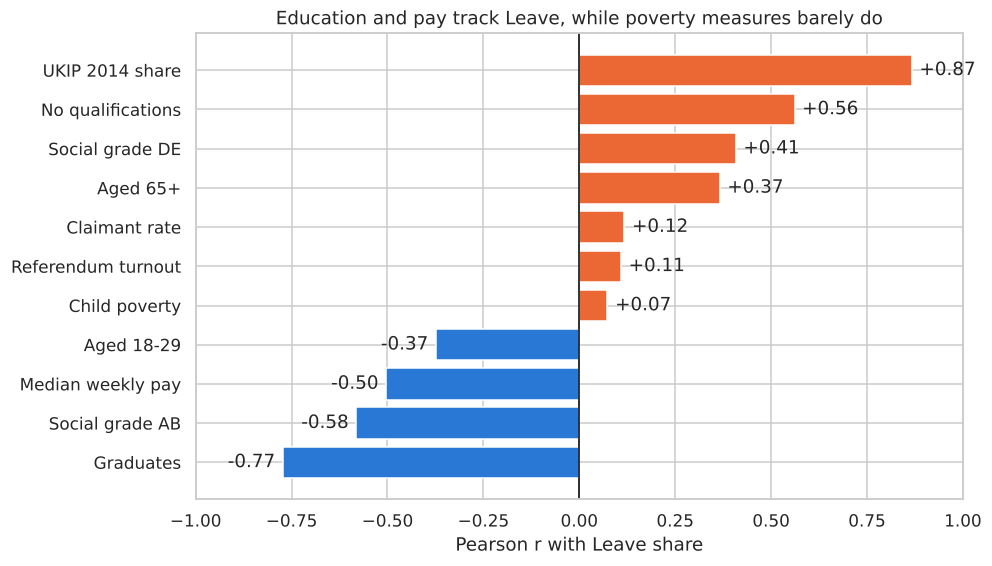

In [12]:
# Readable names for the measures we want to test
measures = {
    "pct_degree": "Graduates",
    "pct_noqual": "No qualifications",
    "pct_ab": "Social grade AB",
    "pct_de": "Social grade DE",
    "pct_65plus": "Aged 65+",
    "pct_18_29": "Aged 18-29",
    "median_weekly_pay": "Median weekly pay",
    "claimant_rate": "Claimant rate",
    "child_poverty_pct": "Child poverty",
    "ukip_2014_pct": "UKIP 2014 share",
    "turnout_pct": "Referendum turnout",
}

# Calculate r for each measure and sort from most negative to most positive
correlations = areas[list(measures)].corrwith(areas["leave_pct"]).rename(measures).sort_values()

# Blue for negative bars, orange for positive bars
colours = [SCOTLAND if r < 0 else LONDON for r in correlations]

# Draw a horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(correlations.index, correlations.values, color=colours)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlim(-1, 1)

# Write the value beside each bar
for i, r in enumerate(correlations):
    ax.text(r + (0.02 if r >= 0 else -0.02), i, f"{r:+.2f}", va="center", ha="left" if r >= 0 else "right")

ax.set_title("Education and pay track Leave, while poverty measures barely do")
ax.set_xlabel("Pearson r with Leave share")
plt.show()

**What we see**

- **UKIP 2014 share (+0.87)** is the strongest link. It measures earlier political support, so it's more a sign of the same attitudes than an explanation of them.
- **Graduates (-0.77)** is the strongest demographic link. Social grade AB (-0.58) and pay (-0.50) point the same way.
- **No qualifications (+0.56)** and **social grade DE (+0.41)** point the other way.
- **Age** matters less at this level: +0.37 for 65+ and -0.37 for 18 to 29.
- **Claimant rate (+0.12)** and **child poverty (+0.07)** are close to zero, so these measures of hardship don't track Leave across Great Britain.
- **Turnout (+0.11)** has little link with the result.

**Be careful:** r shows only straight-line links between areas. It doesn't show cause, and it doesn't describe individual people. A Scottish effect can also hide a link: poverty may behave differently once we compare areas within each nation, which notebook 02 tests.

### Do some measures repeat the same information?

If two measures are very highly correlated, they tell the model almost the same thing. This is called **collinearity**, and it makes regression coefficients hard to read. The heatmap checks our education and social grade measures.

**What this cell does:** `.corr()` calculates r between every pair of measures, and `sns.heatmap()` shows the result as a coloured grid.

**How to read this chart:** find one measure in a row and another in a column. The square where they meet shows their r. Dark red is a strong positive link, dark blue is a strong negative link, and white is a weak link. The diagonal is always 1.00, because each measure matches itself perfectly.

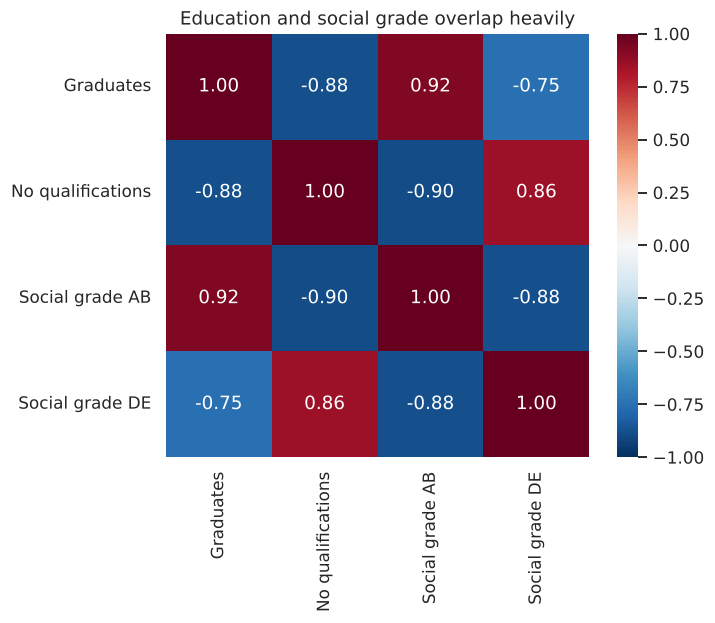

In [13]:
# Correlations between the education and social grade measures
cols = ["pct_degree", "pct_noqual", "pct_ab", "pct_de"]
matrix = areas[cols].rename(columns=measures).corr()

# Draw the heatmap: blue and red are strong, white is weak
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Education and social grade overlap heavily")
plt.show()

**What we see:** these four measures overlap heavily, with r between 0.75 and 0.92 in size. Graduates and social grade AB (0.92) are almost the same signal. This makes sense, because many people in professional jobs have degrees.

**Why it matters:** if we put all four in a regression, the model can't separate their effects, and their coefficients become unstable.

**Decision for the model:** use only one or two of these measures, or use a regularised model such as Ridge.

## 8. Where does the graduate explanation break?

Graduate share is our strongest demographic measure, so we use it to look for exceptions.

We fit a straight trend line using only the areas outside Scotland and London. Then we check how far those two groups sit from that line. If they followed the same pattern, they would sit on it.

**What this cell does**

- It splits the areas into Scotland, London and the rest of Great Britain.
- `np.polyfit(..., deg=1)` finds the straight line that best fits the rest of Great Britain.
- It uses that line to calculate `expected_leave` for every area.
- `residual` is the actual Leave share minus the expected share.

**How to read a residual:** a negative value means the area voted Leave less than its graduate share suggests, and a positive value means it voted Leave more. Think of it as the part of the vote that graduate share doesn't explain.

We fit the line without Scotland and London so that those two groups can't pull it towards themselves.

In [14]:
# Split the areas into three groups
is_scotland = areas["nation"] == "Scotland"
is_london = areas["region"] == "London"
rest = areas[~is_scotland & ~is_london]

# Fit the trend line on the rest of Great Britain only
slope, intercept = np.polyfit(rest["pct_degree"], rest["leave_pct"], deg=1)
print(f"Each extra point of graduates goes with {slope:.2f} points of Leave")

# Residual = actual Leave share minus the share the trend line expects
areas["expected_leave"] = intercept + slope * areas["pct_degree"]
areas["residual"] = areas["leave_pct"] - areas["expected_leave"]

# Average gap from the line for each group
print(f"Scotland: {areas.loc[is_scotland, 'residual'].mean():.1f} points")
print(f"London: {areas.loc[is_london, 'residual'].mean():.1f} points")

Each extra point of graduates goes with -1.06 points of Leave
Scotland: -17.4 points
London: -3.1 points


**What we see:** each extra point of graduates goes with about 1.06 fewer points of Leave. So the line predicts roughly 11 points less Leave for an area with 10 more points of graduates. On average, Scotland sits 17.4 points below the line, and London 3.1 points below it.

**What this cell does:** `ax.scatter()` draws one dot per area, one group at a time so each gets its colour. `ax.plot()` adds the trend line.

**How to read this chart:** each dot is one area. Further right means more graduates, and higher means a stronger Leave vote. The dashed line shows what the rest of Great Britain's pattern would predict. Dots on the line fit the pattern, and dots below it voted Leave less than expected.

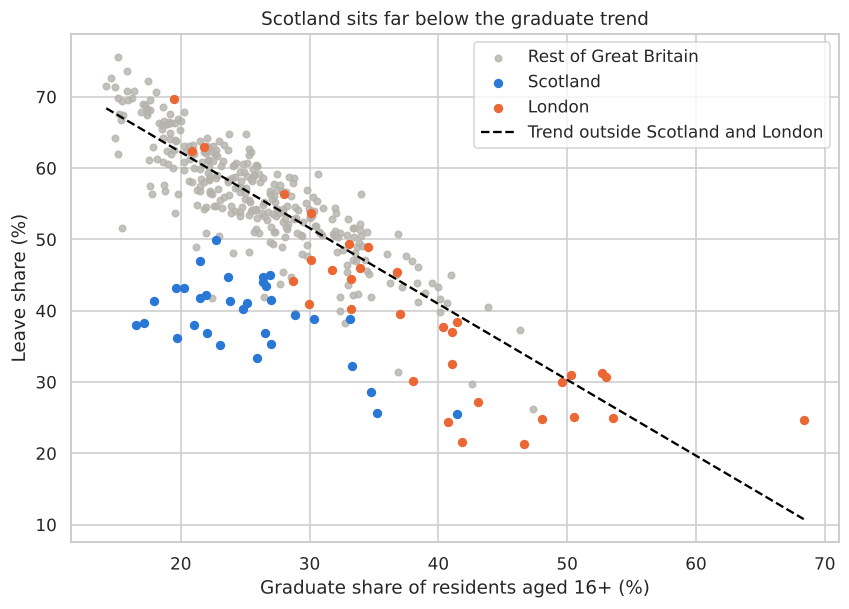

In [15]:
# Plot each group in its own colour
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(rest["pct_degree"], rest["leave_pct"], s=18, color=OTHER, alpha=0.8, label="Rest of Great Britain")
ax.scatter(areas.loc[is_scotland, "pct_degree"], areas.loc[is_scotland, "leave_pct"], s=26, color=SCOTLAND, label="Scotland")
ax.scatter(areas.loc[is_london, "pct_degree"], areas.loc[is_london, "leave_pct"], s=26, color=LONDON, label="London")

# Draw the trend line across the range of the data
x_line = np.array([areas["pct_degree"].min(), areas["pct_degree"].max()])
ax.plot(x_line, intercept + slope * x_line, color="black", linestyle="--", label="Trend outside Scotland and London")

# Label the chart
ax.set_title("Scotland sits far below the graduate trend")
ax.set_xlabel("Graduate share of residents aged 16+ (%)")
ax.set_ylabel("Leave share (%)")
ax.legend()
plt.show()

**What we see**

- Grey dots follow the line closely, so graduate share fits the rest of Great Britain well.
- All 32 Scottish councils sit below the line, whatever their graduate share.
- London's dots stay close to the line, and 12 of its 33 areas sit above it. London mostly fits because it has many graduates.

**Why it matters:** this gives two different stories. Graduate share goes a long way towards explaining London, but it can't explain Scotland, where something else is lowering the Leave vote.

**What this cell does:** `.nsmallest()` and `.nlargest()` find the 8 areas furthest below and above the line. These are the outliers, which show where the explanation fails.

In [16]:
# Which areas are furthest from the trend, in either direction?
show = ["area", "region", "pct_degree", "leave_pct", "expected_leave", "residual"]

print("Most below the trend (lower Leave than expected)")
display(areas.nsmallest(8, "residual")[show].round(1))

print("Most above the trend (higher Leave than expected)")
display(areas.nlargest(8, "residual")[show].round(1))

Most below the trend (lower Leave than expected)


,area,region,pct_degree,leave_pct,expected_leave,residual
351,West Dunbartonshire,Scotland,16.5,38.0,65.9,-27.9
355,North Lanarkshire,Scotland,17.2,38.3,65.3,-26.9
335,Inverclyde,Scotland,19.7,36.2,62.5,-26.3
350,Renfrewshire,Scotland,23.1,35.2,59.0,-23.8
336,Midlothian,Scotland,21.1,37.9,61.1,-23.2
344,South Lanarkshire,Scotland,22.0,36.9,60.1,-23.1
328,East Ayrshire,Scotland,17.9,41.4,64.5,-23.1
357,Glasgow City,Scotland,25.9,33.4,55.9,-22.5


Most above the trend (higher Leave than expected)


,area,region,pct_degree,leave_pct,expected_leave,residual
293,City of London,London,68.4,24.7,10.8,13.9
152,Ribble Valley,North West,34.0,56.4,47.4,9.0
100,Brentwood,East,30.7,59.2,50.9,8.3
164,Boston,East Midlands,15.1,75.6,67.4,8.1
213,South Staffordshire,West Midlands,25.1,64.8,56.8,8.0
33,Thurrock,East,17.4,72.3,65.0,7.3
168,South Holland,East Midlands,15.8,73.6,66.7,6.9
308,Havering,London,19.4,69.7,62.8,6.8


**What we see**

- The 8 areas furthest below the line are all Scottish. West Dunbartonshire is 27.9 points below it, and Glasgow 22.5 points below.
- Above the line, City of London is highest at +13.9 points. It is very small and unusual, with few residents and a high graduate share.
- Several other areas above the line, such as Boston, South Holland and Thurrock, are in eastern England. Havering shows that outer London can behave the same way.

**Why it matters:** outliers give us questions for the statistical tests (notebook 02) and the machine-learning model. They show where the model should fail, and where we need other measures.

## 9. Scotland: Remain 2016 vs Yes 2014

If Scotland's low Leave vote were about nationalism, we would expect Yes areas to be the strongest Remain areas. We test this across the 32 councils.

**What this cell does**

- `stats.pearsonr()` gives r and a p-value for each pair.
- The p-value shows how often a link this strong could appear by chance if there were no real link. A value below 0.05 is the usual cut-off. With only 32 councils, chance matters more than it does with 380 areas.
- The loop draws both charts, and `ax.annotate()` names three councils.

**How to read these charts:** each dot is one council, and height shows its Yes vote. Dots above the dashed line voted Yes in 2014. In a real link, dots form a sloping band. In the left chart they form a loose cloud. In the right chart they rise from left to right.

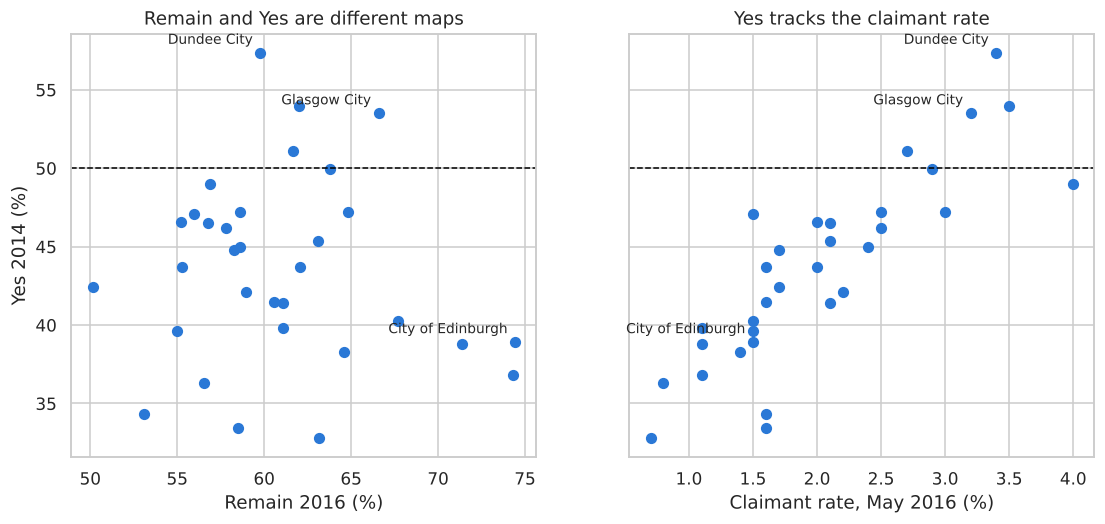

Remain vs Yes: r = -0.10, p = 0.60
Claimant rate vs Yes: r = 0.85, p = 9.0e-10


In [17]:
# Correlation between Remain 2016 and Yes 2014, with its p-value
r, p = stats.pearsonr(scotland["remain_pct"], scotland["yes_pct"])
print(f"Remain vs Yes: r = {r:.2f}, p = {p:.2f}")

# Correlation between Yes 2014 and claimant rate
r2, p2 = stats.pearsonr(scotland["claimant_rate"], scotland["yes_pct"])
print(f"Claimant rate vs Yes: r = {r2:.2f}, p = {p2:.1e}")

# Two charts side by side, sharing the Yes axis
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
pairs = [("remain_pct", "Remain 2016 (%)", "Remain and Yes are different maps"),
         ("claimant_rate", "Claimant rate, May 2016 (%)", "Yes tracks the claimant rate")]

# The same steps run for each chart
for ax, (column, label, title) in zip(axes, pairs):
    ax.scatter(scotland[column], scotland["yes_pct"], color=SCOTLAND, s=40)
    ax.axhline(50, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(label)
    ax.set_title(title)

    # Name a few councils so the chart is easier to read
    for name in ["Dundee City", "Glasgow City", "City of Edinburgh"]:
        row = scotland[scotland["area"] == name].iloc[0]
        ax.annotate(name, (row[column], row["yes_pct"]), xytext=(-5, 6), textcoords="offset points", ha="right", fontsize=9)

axes[0].set_ylabel("Yes 2014 (%)")
plt.show()

**What we see**

- **Remain vs Yes:** r = -0.10 with p = 0.60, so there's no clear link. Edinburgh had the highest Remain share (74.4%) but only 38.9% Yes, while Dundee had 59.8% Remain and the highest Yes share (57.3%).
- **Yes vs claimant rate:** r = 0.85, a strong link. Orkney has the lowest claimant rate (0.7%) and the lowest Yes share (32.8%), while West Dunbartonshire has a 3.5% rate and 54.0% Yes.

**Why it matters:** Remain doesn't appear to be simply the same vote as Yes. The two referendums seem to divide Scotland along different lines.

**Be careful:** this describes one past vote across 32 areas, and it isn't a forecast of a future referendum. The claimant rate is from May 2016, two years after the 2014 vote, and it shows a link, not a cause.

## 10. *(Optional)* The Brexit debate on Twitter around the vote

**This section is optional.** The main project is about the vote across areas. Tweets can't be used in that analysis, because they have no local geography: we don't know which area each tweet came from. If you keep a Twitter part in the presentation, it stays limited to **Brexit tweets around the time of the vote**, to show how the online debate moved. There is no disinformation analysis.

**The data:** the CEU Brexit stance dataset. Researchers collected UK tweets about Brexit from 12 May to 25 June 2016, and a computer model labelled each one **Leave**, **Remain** or **Neutral**. We only have the counts per day, not the tweet text.

The file has one row per day. We keep only full days **before** polling day (23 June), so reactions to the result don't affect the trend.

`leave_share_decided` is the Leave share of tweets that took a side, leaving out neutral tweets. For example, 70% means that 7 in 10 tweets taking a side were labelled Leave.

**Be careful with this data:**

- The labels come from a machine-learning classifier that was right about 6 times in 10 (59.5% accuracy), so read the **trend**, not the exact levels.
- Twitter users are not a sample of voters: they are younger and more political than average.
- A label says nothing about whether a tweet was true.

**What this cell does**

- `pd.to_datetime()` turns text into real dates, so we can filter and sort by time.
- We keep days before 23 June 2016, which removes polling day and the reaction afterwards. This leaves 42 days and 3,644,361 tweets.
- `.dt.dayofweek` gives the day of the week, so we can compare weekdays and weekends.

In [18]:
# Turn the date text into real dates
tweets["date"] = pd.to_datetime(tweets["date_utc"].str[:10])

# Keep only the days before polling day
before = tweets[tweets["date"] < "2016-06-23"].copy()
print("Days kept:", len(before))
print("Tweets kept:", int(before["total"].sum()))

# Flag weekends: Monday is 0, so Saturday is 5 and Sunday is 6
before["weekend"] = before["date"].dt.dayofweek >= 5
print(before.groupby("weekend")["leave_share_decided"].mean().round(3))

Days kept: 42
Tweets kept: 3644361
weekend
False    0.68
True     0.72
Name: leave_share_decided, dtype: float64


**What this cell does:** it creates two charts sharing one date axis. The top one is a line of the daily Leave share, and the bottom one shows tweets per day as bars. We use two charts because the measures have very different scales, and one chart with two scales can mislead.

**How to read these charts:** in the top chart, a value of 70% means 7 in 10 tweets taking a side were labelled Leave. Its axis doesn't start at 0, so it makes changes look bigger than they are. The dashed line marks 16 June. The bottom chart shows how much data sits behind each day.

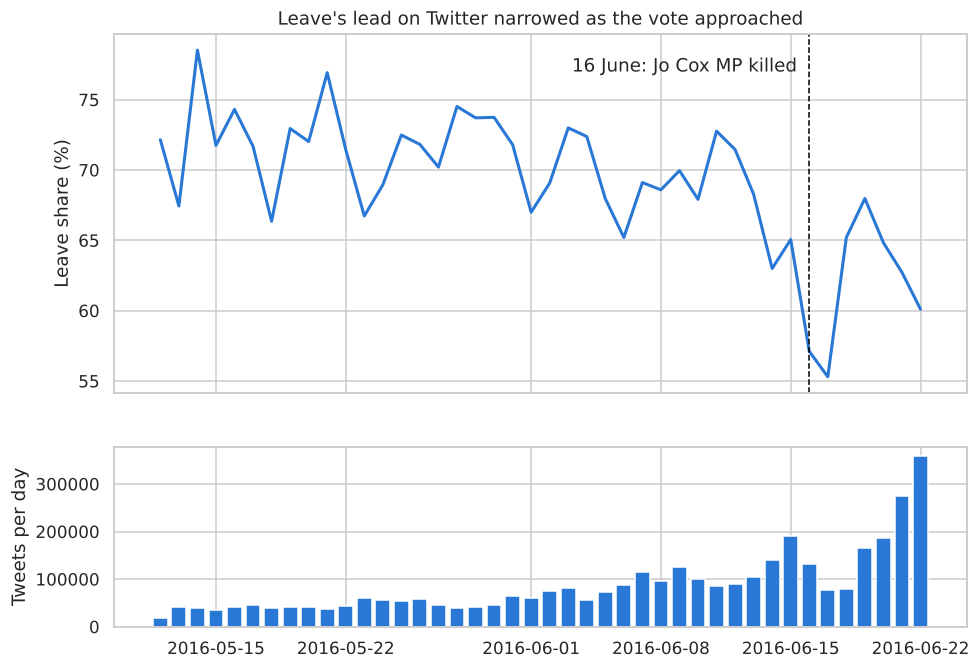

In [19]:
# Two charts stacked, sharing the same date axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# Top chart: Leave share per day
ax1.plot(before["date"], before["leave_share_decided"] * 100, color=SCOTLAND, linewidth=2)
ax1.set_ylabel("Leave share (%)")
ax1.set_title("Leave's lead on Twitter narrowed as the vote approached")

# Mark 16 June. This shows timing only, not cause
ax1.axvline(pd.Timestamp("2016-06-16"), color="black", linestyle="--", linewidth=1)
ax1.annotate("16 June: Jo Cox MP killed", (pd.Timestamp("2016-06-16"), 77), xytext=(-8, 0),
             textcoords="offset points", ha="right")

# Bottom chart: number of tweets per day
ax2.bar(before["date"], before["total"], color=SCOTLAND)
ax2.set_ylabel("Tweets per day")
plt.show()

**What we see**

- **Leave led every day.** Its share of tweets taking a side never fell below 55%.
- **The lead narrowed.** The average was about 72% in the first three weeks, and about 62% in the final seven days.
- **Weekends run higher,** at 72% against 68% on weekdays. The peak was Saturday 14 May, at 78.5%. So compare weeks, not single days.
- **The lowest point** was 17 June, at 55.3%, the day after Jo Cox MP was killed. The chart shows only the timing, so we can't say the event caused the fall.
- **Volume grew sharply,** from about 40,000 tweets a day in mid-May to 359,674 on 22 June.

**Be careful:** Leave's share on 22 June was 60.1%, well above its actual result of 51.9%. Twitter users aren't a sample of voters, and the labels come from a classifier, so this shows how the debate moved, not how people would vote. A label also says nothing about whether a tweet was true.

12 May is a part day, and 18 June is missing one hour.

## 11. Export a file for the Tableau dashboards

The next step of the project is to build the **Tableau dashboards**. Tableau works best with one clean table where each row is one area and each column is something we want to show. This section builds that table from what we calculated above and saves it as a CSV file.

**What this cell does, step by step**

1. It starts from the `areas` table, which already holds the votes and area characteristics.
2. It adds the columns we created in this notebook:
   - `region_leave_pct`: the Leave share of the whole region, from total votes (section 6).
   - `expected_leave` and `residual`: what the graduate trend line expected, and the gap from it (section 8). A negative residual means the area voted Leave **less** than its graduate share suggests.
3. It adds the 2014 independence vote (`yes_2014_pct`) for the 32 Scottish councils. Other areas stay blank, because the 2014 vote happened only in Scotland.
4. It adds a `group` column (Scotland, London or Rest of GB), useful for colours and filters in Tableau.
5. It keeps only the columns useful for the dashboards and saves them as `tableau_areas.csv` in the Data Project folder.

**How to use it in Tableau**

1. Open Tableau and connect to **Spatial file**, then choose `gb_areas_boundaries.geojson`. Tableau reads the outlines of the 380 areas.
2. Add a second connection: **Text file**, then choose `tableau_areas.csv`.
3. Join the two on the area code: `code` in both files.
4. Drag the geometry onto the view to draw the map, then drag a column such as `leave_pct` or `residual` onto **Colour**.

**Dashboard ideas from this notebook:** a Leave share map by area, a region comparison, the graduate scatter with the trend line, and a "gap from the trend" map that shows Scotland standing out.

In [20]:
# Start from the areas table and keep the columns we want to show
tableau = areas[["code", "area", "region", "nation", "electorate", "valid_votes", "leave_votes", "remain_votes",
                 "leave_pct", "remain_pct", "turnout_pct", "pct_degree", "pct_noqual", "pct_ab", "pct_de",
                 "pct_65plus", "pct_18_29", "median_weekly_pay", "claimant_rate", "child_poverty_pct",
                 "ukip_2014_pct", "expected_leave", "residual"]].copy()

# The region's Leave share, calculated from total votes (section 6)
tableau["region_leave_pct"] = tableau["region"].map(region_leave)

# The 2014 independence vote, for Scottish councils only (blank elsewhere)
tableau["yes_2014_pct"] = tableau["code"].map(scotland.set_index("code")["yes_pct"])

# A group column for colours and filters
tableau["group"] = np.select([tableau["nation"] == "Scotland", tableau["region"] == "London"],
                             ["Scotland", "London"], "Rest of GB")

# Round to 2 decimals so the file is easy to read, then save it
tableau = tableau.round(2)
tableau.to_csv(DATA_DIR / "tableau_areas.csv", index=False)

print("Saved tableau_areas.csv:", tableau.shape[0], "rows and", tableau.shape[1], "columns")
print("Areas with a 2014 Yes value:", tableau["yes_2014_pct"].notna().sum())
display(tableau[["area", "group", "leave_pct", "region_leave_pct", "expected_leave", "residual", "yes_2014_pct"]].head())

Saved tableau_areas.csv: 380 rows and 26 columns
Areas with a 2014 Yes value: 32


,area,group,leave_pct,region_leave_pct,expected_leave,residual,yes_2014_pct
0,Hartlepool,Rest of GB,69.57,58.04,64.79,4.78,NaN
1,Middlesbrough,Rest of GB,65.48,58.04,63.79,1.69,NaN
2,Redcar and Cleveland,Rest of GB,66.19,58.04,63.38,2.81,NaN
3,Stockton-on-Tees,Rest of GB,61.73,58.04,59.24,2.49,NaN
4,Darlington,Rest of GB,56.18,58.04,58.28,-2.10,NaN


**What we see:** the file has 380 rows, one per area, and 26 columns. 32 rows have a 2014 Yes value: the Scottish councils. The first rows are English areas, so their `yes_2014_pct` is blank (NaN), which is expected.

**Check before using it:** the area codes in this file match the codes in the boundaries file, so the join in Tableau should match all 380 areas. If Tableau shows fewer, check that both files use the column `code`.

## 12. Main findings and next steps

**Findings**

- 263 of 380 areas voted Leave, and no Scottish council did.
- The maps show Remain in Scotland, London and several cities, and strong Leave areas in eastern England.
- Graduate share has the strongest demographic link with Leave (r = -0.77).
- Scottish councils sit about 17 points below the graduate trend from the rest of Great Britain.
- Claimant rate and child poverty show almost no link with Leave across Great Britain.
- In Scotland, Remain 2016 and Yes 2014 are not linked (r = -0.10), but Yes follows the claimant rate (r = 0.85).
- *(Optional)* On Twitter, Leave's lead narrowed in the final weeks before the vote.

**Decisions for the next steps**

- Keep `pct_nonuk_born` and `imd_score_england` out of the Great Britain model, because they don't cover all of Great Britain.
- Use only one or two education and social grade measures, because they repeat each other.
- Report the model with and without UKIP 2014 share: one explains, the other only predicts.
- Test the model on regions it hasn't seen, because Scotland is where it should struggle.

**Next steps in the project**

1. **Notebook 02:** test these patterns with statistical tests: are they real, and how big are they?
2. **Notebook 03:** look at Scotland in more depth.
3. **Tableau dashboards:** start from `tableau_areas.csv` (section 11).
4. **Machine learning:** predict each area's Leave share and study where the model fails.

## 13. The whole notebook in simple words

This notebook explores the clean data to answer one question: **what explains the Leave vote, and where does that explanation stop working?** It only looks for patterns at this stage. Testing them comes in notebook 02.

**Step by step**

1. **Setup and loading:** we import the Python tools and open the data files.
2. **Data check:** we look for duplicates and missing values. There are no duplicates. Two columns have large gaps, so they stay out of the Great Britain model.
3. **Histogram:** this shows how many areas fall into each band of Leave share. 263 of 380 areas voted Leave, and many were only just above 50%.
4. **Regions chart:** each dot is an area. No Scottish council reached 50% Leave. London has the widest range, from 21.4% to 69.7%, so "London voted Remain" hides big differences.
5. **Maps:** these show where the votes were. Scotland, London and cities like Cambridge lean Remain, while eastern England is strongly Leave. Big rural areas look important, but they hold fewer voters.
6. **Correlation chart:** this ranks what moves with Leave.
   - **UKIP 2014 (+0.87):** the strongest link, but it's mostly the same political mood seen two years earlier.
   - **Graduates (-0.77):** more graduates usually means less Leave. This is the strongest demographic link.
   - **Claimant rate (+0.12) and child poverty (+0.07):** almost no link across Great Britain.
7. **Heatmap:** education and social grade overlap heavily, so the model should use only one or two of them.
8. **Graduate trend chart:** outside Scotland and London, 1 extra point of graduates goes with about 1.06 fewer points of Leave. London stays fairly close to the line, so graduates explain much of its result. Scotland sits about 17 points below it, so **something else is going on there**.
9. **Scotland charts:**
   - **Remain vs Yes (r = -0.10, p = 0.60):** no clear link. Edinburgh was strongly Remain but voted No in 2014.
   - **Yes vs claimant rate (r = 0.85):** a strong link. Areas with more people claiming benefits tended to vote Yes.
10. *(Optional)* **Twitter charts:** Leave led every day, but its share fell from about 72% to about 62% near the end. Twitter users aren't typical voters, and a computer model labelled the tweets, so this shows how the debate moved, not how people would vote.
11. **Tableau export:** we save one clean table, `tableau_areas.csv`, ready to join with the map outlines in Tableau.

**The main story**

Education explains much of the Leave vote across England and Wales, but it doesn't explain Scotland.

These results describe **areas, not individual people**. A low-graduate area voting Leave doesn't tell us how any one person there voted.